# Step 3: Exploratory Data Analysis & Visualizations

Generates, displays, and saves:
1. **Class Distribution Bar Plot**
2. **Audio Duration Histograms (Before vs. After Equalization)**
3. **Waveform Comparisons (Real vs. Synthetic Speech)**
4. **Log Mel-Spectrogram Comparisons**

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns

BASE_DIR = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
DATA_PROCESSED_DIR = BASE_DIR / "data" / "processed_clean"
GRAPHS_DIR = BASE_DIR / "graphs"
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)

manifest_df = pd.read_csv(DATA_PROCESSED_DIR / "manifest.csv")
print(f"Loaded manifest with {len(manifest_df):,} records.")


Loaded manifest with 3,000 records.


### 1. Class Distribution Bar Plot

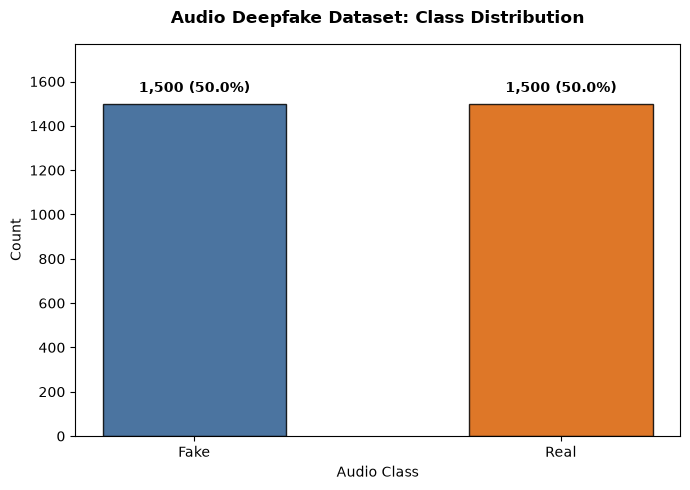

In [2]:
counts = manifest_df["label"].value_counts()
labels = counts.index.tolist()
values = counts.values.tolist()

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(labels, values, color=["#2b5c8f", "#d95f02"], width=0.5, edgecolor="black", alpha=0.85)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:,} ({height/len(manifest_df)*100:.1f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 6), textcoords="offset points", ha="center", va="bottom", fontweight="bold")

ax.set_title("Audio Deepfake Dataset: Class Distribution", fontweight="bold", pad=15)
ax.set_xlabel("Audio Class")
ax.set_ylabel("Count")
ax.set_ylim(0, max(values) * 1.18)
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "01_class_distribution.png", dpi=300)
plt.show()


### 2. Audio Duration Histograms: Before vs. After Equalization

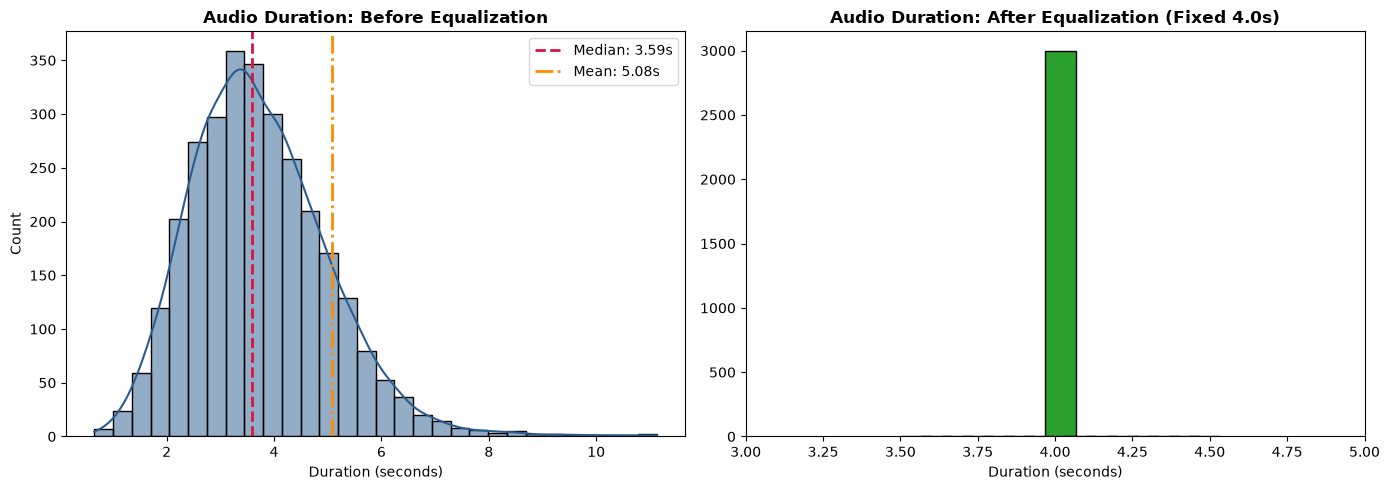

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Before equalization
orig_durs = manifest_df["orig_duration"].values
sns.histplot(orig_durs[orig_durs <= 12], bins=30, kde=True, ax=ax1, color="#2b5c8f", edgecolor="black")
ax1.axvline(np.median(orig_durs), color="crimson", linestyle="--", linewidth=2, label=f"Median: {np.median(orig_durs):.2f}s")
ax1.axvline(np.mean(orig_durs), color="darkorange", linestyle="-.", linewidth=2, label=f"Mean: {np.mean(orig_durs):.2f}s")
ax1.set_title("Audio Duration: Before Equalization", fontweight="bold")
ax1.set_xlabel("Duration (seconds)")
ax1.set_ylabel("Count")
ax1.legend()

# After equalization
proc_durs = manifest_df["proc_duration"].values
ax2.hist(proc_durs, bins=15, color="#2ca02c", edgecolor="black", width=0.1, align="mid")
ax2.set_title("Audio Duration: After Equalization (Fixed 4.0s)", fontweight="bold")
ax2.set_xlabel("Duration (seconds)")
ax2.set_xlim(3.0, 5.0)

plt.tight_layout()
plt.savefig(GRAPHS_DIR / "02_duration_distribution_before_after.png", dpi=300)
plt.show()


### 3. Waveform Comparison (Real vs. Synthetic Speech)

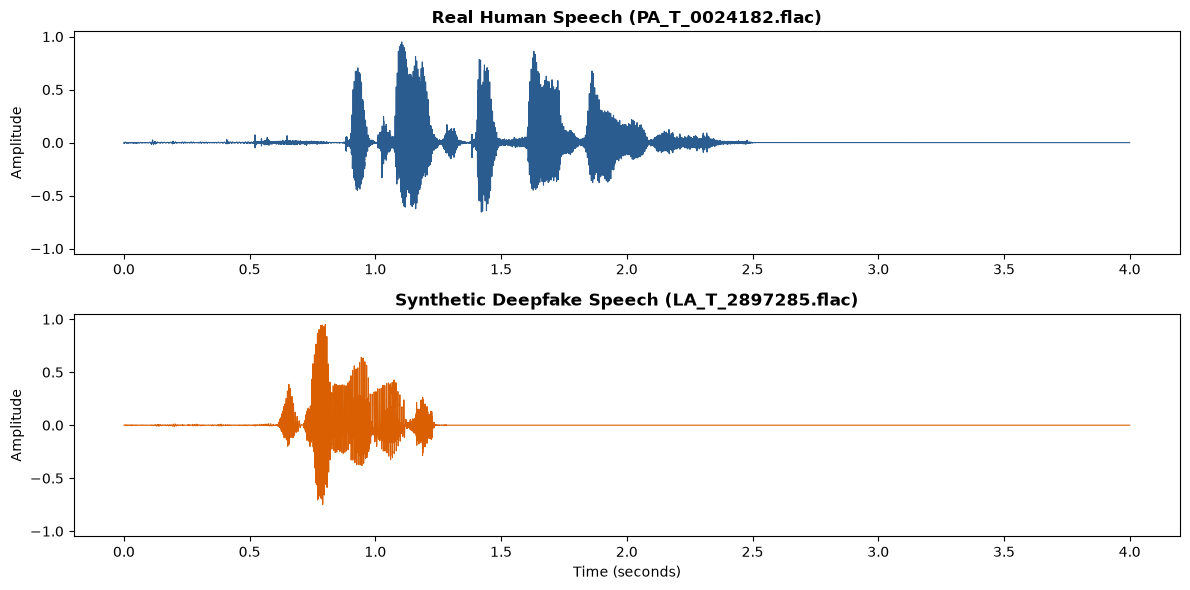

In [4]:
real_row = manifest_df[manifest_df["label"] == "Real"].iloc[0]
fake_row = manifest_df[manifest_df["label"] == "Fake"].iloc[0]

real_data, sr_real = sf.read(real_row["proc_path"])
fake_data, sr_fake = sf.read(fake_row["proc_path"])

time_real = np.linspace(0, len(real_data) / sr_real, len(real_data))
time_fake = np.linspace(0, len(fake_data) / sr_fake, len(fake_data))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharey=True)
ax1.plot(time_real, real_data, color="#2b5c8f", linewidth=0.8)
ax1.set_title(f"Real Human Speech ({real_row['file_name']})", fontweight="bold")
ax1.set_ylabel("Amplitude")
ax1.set_ylim(-1.05, 1.05)

ax2.plot(time_fake, fake_data, color="#d95f02", linewidth=0.8)
ax2.set_title(f"Synthetic Deepfake Speech ({fake_row['file_name']})", fontweight="bold")
ax2.set_xlabel("Time (seconds)")
ax2.set_ylabel("Amplitude")
ax2.set_ylim(-1.05, 1.05)

plt.tight_layout()
plt.savefig(GRAPHS_DIR / "03_waveform_comparison.png", dpi=300)
plt.show()


### 4. Log Mel-Spectrogram Comparisons

e:\Deepfake\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


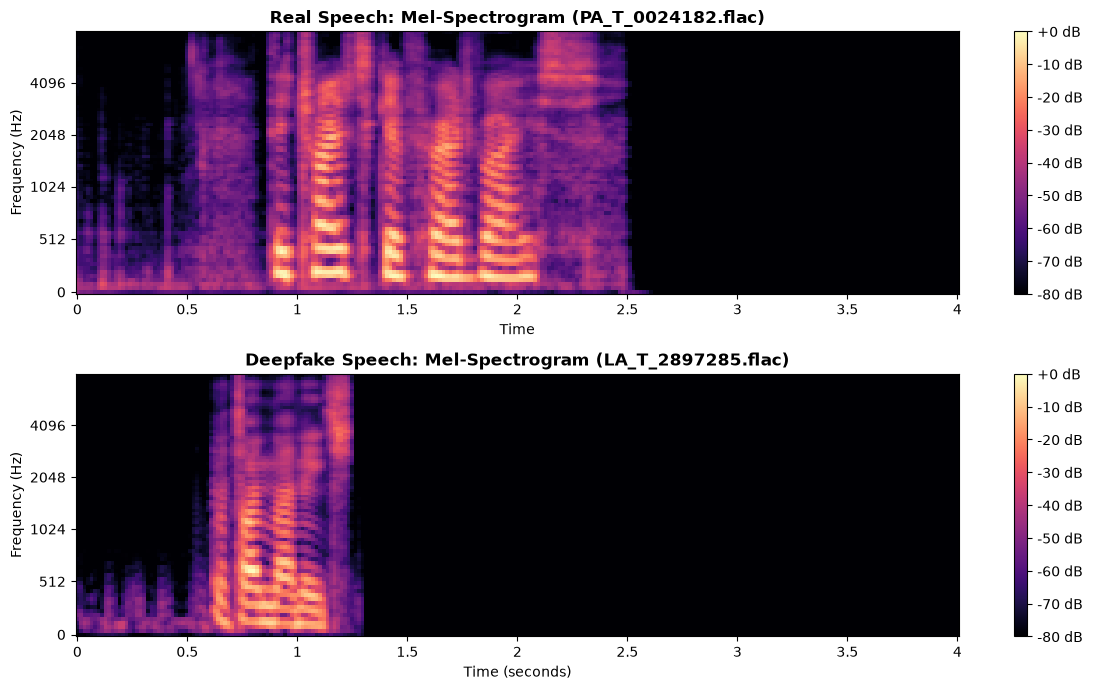

In [5]:
mel_real = librosa.feature.melspectrogram(y=real_data, sr=sr_real, n_fft=1024, hop_length=256, n_mels=80)
mel_real_db = librosa.power_to_db(mel_real, ref=np.max)

mel_fake = librosa.feature.melspectrogram(y=fake_data, sr=sr_fake, n_fft=1024, hop_length=256, n_mels=80)
mel_fake_db = librosa.power_to_db(mel_fake, ref=np.max)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7))
img1 = librosa.display.specshow(mel_real_db, x_axis="time", y_axis="mel", sr=sr_real, hop_length=256, ax=ax1, cmap="magma")
ax1.set_title(f"Real Speech: Mel-Spectrogram ({real_row['file_name']})", fontweight="bold")
ax1.set_ylabel("Frequency (Hz)")
fig.colorbar(img1, ax=ax1, format="%+2.0f dB")

img2 = librosa.display.specshow(mel_fake_db, x_axis="time", y_axis="mel", sr=sr_fake, hop_length=256, ax=ax2, cmap="magma")
ax2.set_title(f"Deepfake Speech: Mel-Spectrogram ({fake_row['file_name']})", fontweight="bold")
ax2.set_xlabel("Time (seconds)")
ax2.set_ylabel("Frequency (Hz)")
fig.colorbar(img2, ax=ax2, format="%+2.0f dB")

plt.tight_layout()
plt.savefig(GRAPHS_DIR / "04_mel_spectrogram_comparison.png", dpi=300)
plt.show()
